--------
## Name - Adesh Rodiye
## PRN - 8005 
---------

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [24]:
RANDOM_STATE=24
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(seed = RANDOM_STATE)

NOISE=0.2
EPOCHS=20001
ALPHA=0.1   # learning rate
N_SAMPLES=1000   # no. of samples to create
TEST_SIZE=0.2
params={
    'legend.fontsize': 'medium',
    'figure.figsize': (15,6),
    'axes.labelsize': 'medium',
    'axes.titlesize': 'medium',
    'xtick.labelsize': 'medium',
    'ytick.labelsize': 'medium'
}

plt.rcParams.update(params)
CMAP=plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid')

In [25]:
def plot_decision_boundary(model:dict,
                           X_tr:np.ndarray,
                           y_tr:np.ndarray,
                           X_ts:np.ndarray,
                           y_ts:np.ndarray
                          ):
    fig, ax = plt.subplots()
    dm = 0.005
    margin = 10*dm
    xMin = min(X_tr[:, 0].min() - margin, X_ts[:, 0].min() - margin)
    xMax = max(X_tr[:, 0].max() + margin, X_ts[:, 0].max() + margin)
    yMin = min(X_tr[:, 1].min() - margin, X_ts[:, 1].min() - margin)
    yMax = max(X_tr[:, 1].max() + margin, X_ts[:, 1].max() + margin)

    xx ,yy = np.meshgrid(np.arange(xMin, xMax, dm), np.arange(yMin, yMax, dm))

    XX = np.c_[xx.ravel(), yy.ravel()]
    Z = fn_predict(model,XX).reshape(xx.shape)
    ax.contourf(xx,yy, Z, cmap=plt.cm.Paired, alpha=0.6)
    ax.scatter(X_tr[:,0], X_tr[:,1], c = y_tr, s=30, edgecolors='k', cmap=CMAP)
    ax.scatter(X_ts[:,0], X_ts[:,1], c = y_ts, s=30, marker='*', edgecolors='k', cmap=plt.cm.seismic)
    ax.set_xlabel('Featre 1')
    ax.set_ylabel('Feature 2')
    ax.set_title('Decision Boundary')
    ax.legend()

In [26]:
X,y = datasets.make_moons(n_samples=N_SAMPLES, shuffle=True, noise=NOISE, random_state=RANDOM_STATE)
X[:5], y[:5]

(array([[ 0.90633951,  0.90267624],
        [-1.11536828,  0.75579289],
        [ 1.88769158,  0.4175967 ],
        [-0.93345034, -0.02299851],
        [-0.96872877,  0.06396285]]),
 array([0, 0, 1, 0, 0]))

In [27]:
data_df = pd.DataFrame(X, columns=['A', 'B'])
data_df['target'] = y
data_df.head()

,A,B,target
0,0.906340,0.902676,0
1,-1.115368,0.755793,0
2,1.887692,0.417597,1
3,-0.933450,-0.022999,0
4,-0.968729,0.063963,0


In [28]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=TEST_SIZE,random_state=RANDOM_STATE,stratify=y)
print(X_train.shape,X_test.shape,y_train.shape,y_test.shape)

(800, 2) (200, 2) (800,) (200,)


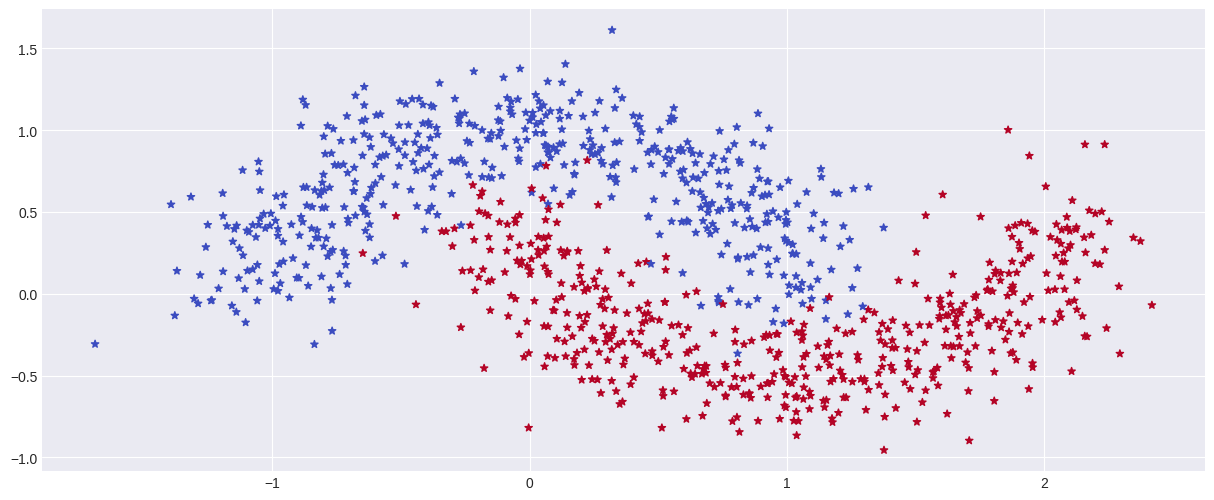

In [29]:
plt.figure()
plt.scatter(X[:,0],X[:,1],s=30,c=y,marker='*',cmap=CMAP)

### Sigmoid Activation Function

In [30]:
def fn_activ(z: np.ndarray) -> np.ndarray:
    return np.tanh(z)

def fn_activ_prime(z: np.ndarray) -> np.ndarray:
    return 1.0 - np.tanh(z)**2

In [31]:
def fn_sigmoid(z):
    return 1/(1+np.exp(-z))

In [32]:
fn_sigmoid(np.asarray([-np.inf,-1,0,+1,np.inf]))

array([0.        , 0.26894142, 0.5       , 0.73105858, 1.        ])

In [33]:
def fn_predict(model: dict,X_p:np.ndarray):
    '''
    model: Dictionary containing weights and bias
    X: input features
    '''
    W1,W2=model['W1'],model['W2']
    b1,b2=model['b1'],model['b2']

    ### Forward propagation
    #Layer1
    z1=X_p.dot(W1)+b1 #Aggregation
    a1=fn_activ(z1) #Activation

    #Layer 2
    z2=a1.dot(W2)
    a2=fn_sigmoid(z2)

    return a2>=0.5


In [34]:
def fn_calculate_loss(model:dict,X_l:np.ndarray,y_l:np.ndarray):
    '''
    model: Dictionary containing weights and bias
    X_l: input_features
    y_l: targets
    '''
    m=X_l.shape[0]
    W1,W2=model['W1'],model['W2']
    b1,b2=model['b1'],model['b2']

    ### Forward propagation
    #Layer1
    z1=X_l.dot(W1)+b1 #Aggregation
    a1=fn_activ(z1) #Activation

    #Layer 2
    z2=a1.dot(W2)
    a2=fn_sigmoid(z2)

    data_loss=-(y_l*np.log(a2)+(1-y_l)*np.log(1-a2)).sum()

    return data_loss/m


In [35]:
def predict(row: np.ndarray, wgts: np.ndarray):
    # row : one sample of data
    # wgts: weight of the model

    z = wgts[0]    #bias
    for i in range(len(row)-1):
        z += wgts[i+1]*row[i]   #aggregation function   z=b0 + b1x1 + b2x2
    return 1 if z>=0 else 0   # simple activation

In [36]:
weights = np.array([0.1, 2.0, 1.0])
display(data_df.loc[0])
predict(data_df.loc[0].values, weights)

,0
A,0.906340
B,0.902676
target,0.000000


1

In [37]:
def fn_build_model(
    nn_hdim:np.int64,
    X:np.ndarray,
    y:np.ndarray,
    alpha:np.float64=ALPHA,
    n_epochs: np.int64=EPOCHS
)->dict:
    '''
    nn_hdim: number of hidden unites,
    X: features,
    y: labels,
    alpha: learning rate,
    n_epochs: number of passes thereough complete data for gradient descen
    '''
    m,nn_input_dim=X.shape
    nn_output_dim=y.shape[1]

    W1=rng.random((nn_input_dim,nn_hdim), dtype=np.float32)/np.sqrt(nn_input_dim)
    W2=rng.random((nn_hdim,nn_output_dim), dtype=np.float32)/np.sqrt(nn_hdim)

    b1=np.zeros((1,nn_hdim),dtype=np.float32)
    b2=np.zeros((1,nn_output_dim),dtype=np.float32)

    curr_loss= 0
    loss,epoch=[],[]

    for i in range(n_epochs):

        ### Forward propagation
        #Layer1
        z1=X.dot(W1)+b1 #Aggregation
        a1=fn_activ(z1) #Activation

        #Layer 2
        z2=a1.dot(W2)
        a2=fn_sigmoid(z2)

        ### Back propagation
        #Layer2
        dz2=a2-y
        dW2=(a1.T).dot(dz2)
        assert(W2.shape==dW2.shape), f'Shape- W2: {W2.shape} | dW2: {dW2.shape}'
        db2=np.sum(dz2,axis=0,keepdims=True)
        assert(b2.shape==db2.shape), f'Shape- b2: {b2.shape} | db2: {db2.shape}'
        da1=dz2.dot(W2.T)
        assert(a1.shape==da1.shape), f'Shape- a1: {a1.shape} | da1: {da1.shape}'

        #Layer1
        dz1=da1*fn_activ_prime(z1)
        dW1=(X.T).dot(dz1)
        assert(W1.shape==dW1.shape), f'Shape- W1: {W1.shape} | dW1: {dW1.shape}'
        db1=np.sum(dz1,axis=0,keepdims=True)
        assert(b1.shape==db1.shape), f'Shape- b1: {b1.shape} | db1: {db1.shape}'

        W1=W1-alpha*dW1/m
        W2=W2-alpha*dW2/m
        b1=b1-alpha*db1/m
        b2=b2-alpha*db2/m

        model ={'W1':W1,'W2':W2,'b1':b1,'b2':b2}

        if i%100==0:
            curr_loss=fn_calculate_loss(model=model,X_l=X,y_l=y)
            loss.append(curr_loss)
            epoch.append(i)
            print(f'Epoch {i:3d}: Loss={curr_loss:.4f}')
    loss_hist['epoch']=epoch
    loss_hist['loss']=loss
    return model

In [38]:
loss_hist={}
y_train=y_train.reshape(-1,1)
model=fn_build_model(4,X_train,y_train)

Epoch   0: Loss=0.6940
Epoch 100: Loss=0.4408
Epoch 200: Loss=0.3315
Epoch 300: Loss=0.3045
Epoch 400: Loss=0.2981
Epoch 500: Loss=0.2963
Epoch 600: Loss=0.2955
Epoch 700: Loss=0.2950
Epoch 800: Loss=0.2946
Epoch 900: Loss=0.2942
Epoch 1000: Loss=0.2938
Epoch 1100: Loss=0.2934
Epoch 1200: Loss=0.2929
Epoch 1300: Loss=0.2923
Epoch 1400: Loss=0.2913
Epoch 1500: Loss=0.2897
Epoch 1600: Loss=0.2870
Epoch 1700: Loss=0.2826
Epoch 1800: Loss=0.2760
Epoch 1900: Loss=0.2673
Epoch 2000: Loss=0.2569
Epoch 2100: Loss=0.2459
Epoch 2200: Loss=0.2349
Epoch 2300: Loss=0.2244
Epoch 2400: Loss=0.2147
Epoch 2500: Loss=0.2059
Epoch 2600: Loss=0.1979
Epoch 2700: Loss=0.1906
Epoch 2800: Loss=0.1841
Epoch 2900: Loss=0.1781
Epoch 3000: Loss=0.1727
Epoch 3100: Loss=0.1677
Epoch 3200: Loss=0.1632
Epoch 3300: Loss=0.1590
Epoch 3400: Loss=0.1551
Epoch 3500: Loss=0.1514
Epoch 3600: Loss=0.1480
Epoch 3700: Loss=0.1447
Epoch 3800: Loss=0.1415
Epoch 3900: Loss=0.1385
Epoch 4000: Loss=0.1355
Epoch 4100: Loss=0.1324
Ep

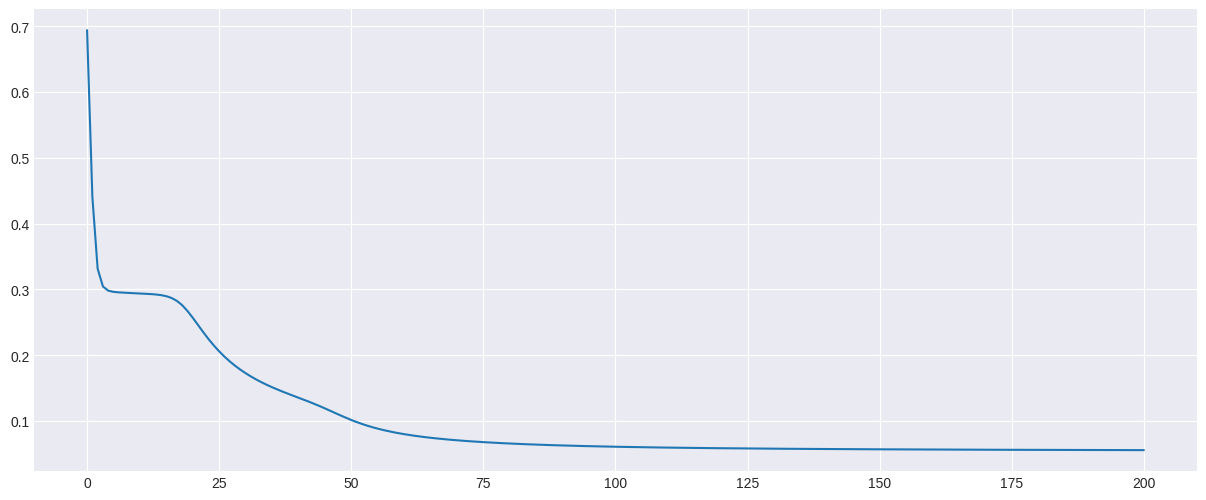

In [39]:
fig,ax = plt.subplots()
ax.plot(loss_hist['loss'])

In [40]:
y_pred=fn_predict(model=model,X_p=X_train)
accuracy_score(y_train,y_pred)

0.9825

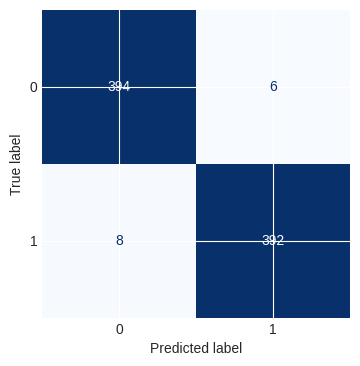

In [41]:
cm=confusion_matrix(y_train,y_pred)
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=[0,1])
fig,ax=plt.subplots(figsize=(4,4))
disp.plot(ax=ax,cmap='Blues',colorbar=False)

/tmp/ipykernel_1916/1652712699.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


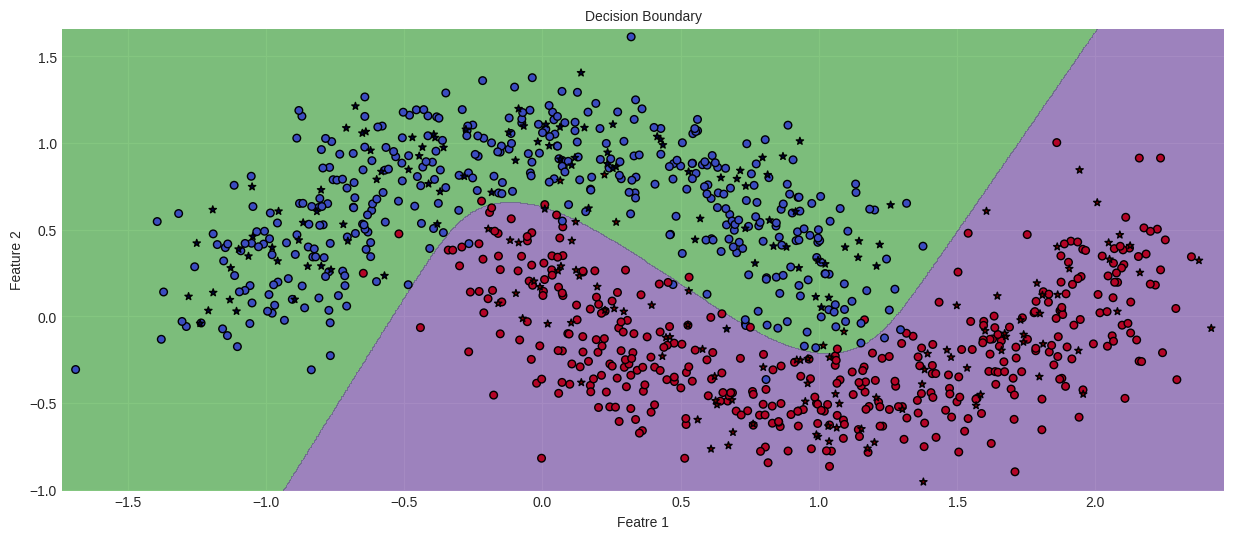

In [42]:
plot_decision_boundary(model, X_train, y_train, X_test, y_test)